### Тема:
«Исследование и сравнение методов понижения размерности и кластеризации на реальном высокоразмерном датасете (из области по выбору: биоинформатика, тексты, изображения, графы) с анализом устойчивости и интерпретируемости полученных кластеров».[7][5]

### Основные требования к проекту:

*   Выбор и обоснование одного или двух реальных высокоразмерных датасетов (например, single‑cell RNA‑seq, embedding‑представления текстов, feature‑описания изображений).[2][5]
*   Построение и сравнение нескольких пайплайнов «DR → кластеризация» (минимум 3 DR‑метода и 3 алгоритма кластеризации) с оценкой качества, устойчивости и практической интерпретации кластеров.[4][12][7]

В проекте используется датасет **USPS** из OpenML: 9298 изображений рукописных цифр размером 16x16 пикселей. Каждое наблюдение описано 256 числовыми признаками яркости пикселей и относится к одному из 10 классов цифр.

Этот датасет выбран, потому что он дает более сложную многоклассовую задачу кластеризации: классы частично пересекаются визуально, признаки высокоразмерные, а истинные метки используются только для внешней оценки качества кластеров.

In [1]:
import time
import warnings
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import fetch_openml
from sklearn.decomposition import PCA, TruncatedSVD
from sklearn.manifold import TSNE
from sklearn.preprocessing import MinMaxScaler
from sklearn.cluster import KMeans, MiniBatchKMeans, AgglomerativeClustering, DBSCAN, OPTICS, Birch
from sklearn.mixture import GaussianMixture
from sklearn.metrics import (
    silhouette_score,
    calinski_harabasz_score,
    davies_bouldin_score,
    adjusted_rand_score,
    adjusted_mutual_info_score,
    normalized_mutual_info_score,
    homogeneity_completeness_v_measure,
)
import umap.umap_ as umap

warnings.filterwarnings('ignore')
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

plt.style.use('default')
sns.set_palette('tab10')

## Загрузка и подготовка данных

Данные загружаются напрямую из OpenML по идентификатору 41082. Используется весь набор из 9298 объектов. Метка `10` в OpenML соответствует цифре `0`, поэтому для интерпретации классов она переводится в `0`.

In [2]:
raw = fetch_openml(data_id=41082, as_frame=False, parser='auto')
X_raw = raw.data.astype(np.float32)
y_raw = raw.target.astype(str)
y_digits = np.where(y_raw == '10', '0', y_raw).astype(int)

# Масштабируем пиксели в диапазон [0, 1], чтобы расстояния и вероятностные модели были сопоставимы.
X = MinMaxScaler().fit_transform(X_raw)
class_names = [str(i) for i in range(10)]
n_classes = len(np.unique(y_digits))

print(f'Размер данных: {X.shape}')
print(f'Количество классов: {n_classes}')
print(f'Диапазон признаков после масштабирования: [{X.min():.3f}, {X.max():.3f}]')
pd.Series(y_digits).value_counts().sort_index().rename('count').to_frame()

Размер данных: (9298, 256)
Количество классов: 10
Диапазон признаков после масштабирования: [0.000, 1.000]


,count
0,821
1,1553
2,1269
3,929
4,824
5,852
6,716
7,834
8,792
9,708


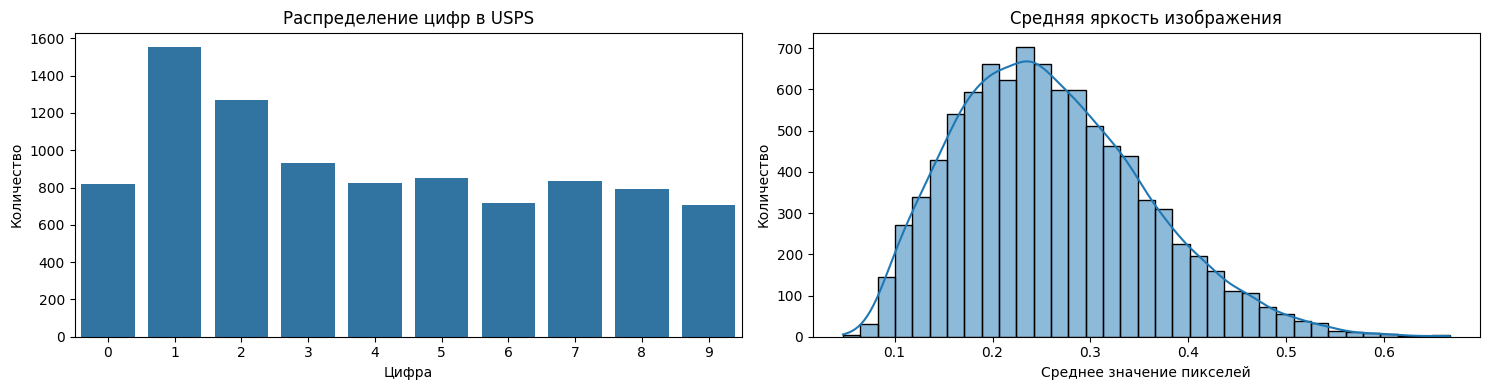

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4))

class_counts = pd.Series(y_digits).value_counts().sort_index()
sns.barplot(x=class_counts.index.astype(str), y=class_counts.values, ax=axes[0])
axes[0].set_title('Распределение цифр в USPS')
axes[0].set_xlabel('Цифра')
axes[0].set_ylabel('Количество')

pixel_activity = X.mean(axis=1)
sns.histplot(pixel_activity, bins=35, kde=True, ax=axes[1])
axes[1].set_title('Средняя яркость изображения')
axes[1].set_xlabel('Среднее значение пикселей')
axes[1].set_ylabel('Количество')

plt.tight_layout()
plt.show()

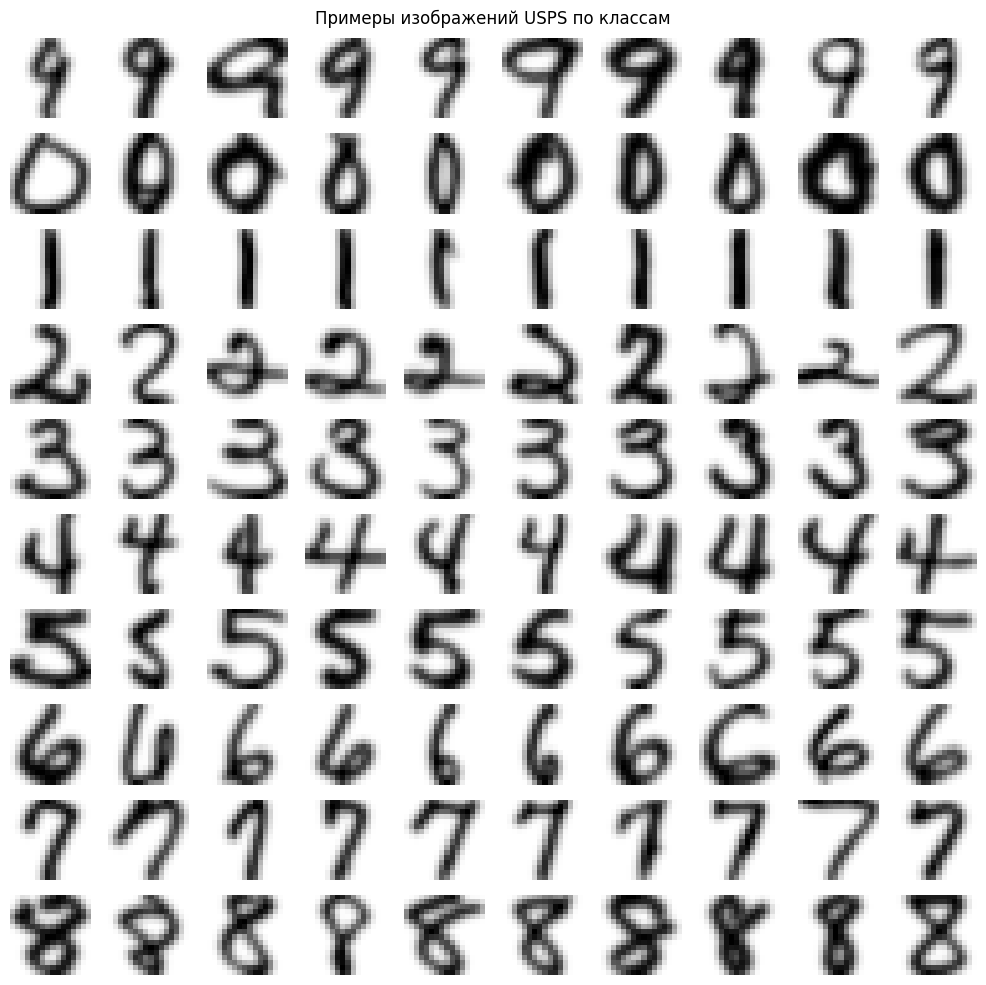

In [4]:
fig, axes = plt.subplots(10, 10, figsize=(10, 10))
for digit in range(10):
    digit_idx = np.where(y_digits == digit)[0][:10]
    for j, idx in enumerate(digit_idx):
        axes[digit, j].imshow(X[idx].reshape(16, 16), cmap='gray_r')
        axes[digit, j].axis('off')
        if j == 0:
            axes[digit, j].set_ylabel(str(digit), rotation=0, labelpad=12, fontsize=12)
plt.suptitle('Примеры изображений USPS по классам')
plt.tight_layout()
plt.show()

## Классы для понижения размерности, кластеризации и оценки

In [5]:
class DRComparer:
    """Сравнение методов понижения размерности для изображений USPS."""

    def __init__(self, random_state=42):
        self.random_state = random_state
        self.dr_results = {}
        self.execution_times = {}
        self.models = {}

    def apply_svd(self, X, n_components=50):
        start = time.time()
        model = TruncatedSVD(n_components=n_components, random_state=self.random_state)
        X_dr = model.fit_transform(X)
        name = f'SVD_{n_components}D'
        self.models[name] = model
        self.dr_results[name] = X_dr
        self.execution_times[name] = time.time() - start
        return X_dr

    def apply_pca(self, X, n_components=50):
        start = time.time()
        model = PCA(n_components=n_components, random_state=self.random_state)
        X_dr = model.fit_transform(X)
        name = f'PCA_{n_components}D'
        self.models[name] = model
        self.dr_results[name] = X_dr
        self.execution_times[name] = time.time() - start
        return X_dr

    def apply_umap(self, X, n_components=2, n_neighbors=30, min_dist=0.1):
        start = time.time()
        model = umap.UMAP(
            n_components=n_components,
            n_neighbors=n_neighbors,
            min_dist=min_dist,
            metric='euclidean',
            random_state=self.random_state,
        )
        X_dr = model.fit_transform(X)
        name = f'UMAP_{n_components}D'
        self.models[name] = model
        self.dr_results[name] = X_dr
        self.execution_times[name] = time.time() - start
        return X_dr

    def apply_tsne(self, X, n_components=2, perplexity=40):
        start = time.time()
        model = TSNE(
            n_components=n_components,
            perplexity=perplexity,
            init='pca',
            learning_rate='auto',
            max_iter=600,
            angle=0.7,
            random_state=self.random_state,
        )
        X_dr = model.fit_transform(X)
        name = 't-SNE_2D'
        self.dr_results[name] = X_dr
        self.execution_times[name] = time.time() - start
        return X_dr

    def apply_all_methods(self, X):
        print('Применение методов понижения размерности...')
        X_svd_50 = self.apply_svd(X, 50)
        print(f"SVD_50D: {self.execution_times['SVD_50D']:.2f} сек")
        self.apply_svd(X, 2)
        print(f"SVD_2D: {self.execution_times['SVD_2D']:.2f} сек")

        X_pca_50 = self.apply_pca(X, 50)
        print(f"PCA_50D: {self.execution_times['PCA_50D']:.2f} сек")
        self.apply_pca(X, 2)
        print(f"PCA_2D: {self.execution_times['PCA_2D']:.2f} сек")

        self.apply_umap(X_pca_50, 50, n_neighbors=30, min_dist=0.05)
        print(f"UMAP_50D: {self.execution_times['UMAP_50D']:.2f} сек")
        self.apply_umap(X_pca_50, 2, n_neighbors=30, min_dist=0.05)
        print(f"UMAP_2D: {self.execution_times['UMAP_2D']:.2f} сек")

        self.apply_tsne(X_pca_50, 2, perplexity=40)
        print(f"t-SNE_2D: {self.execution_times['t-SNE_2D']:.2f} сек")
        return self.dr_results


class ClusteringAlgorithms:
    """Набор алгоритмов кластеризации с единым интерфейсом."""

    def __init__(self, random_state=42):
        self.random_state = random_state

    def kmeans(self, X, n_clusters=10):
        model = KMeans(n_clusters=n_clusters, random_state=self.random_state, n_init=20)
        return model.fit_predict(X), model

    def mini_batch_kmeans(self, X, n_clusters=10):
        model = MiniBatchKMeans(n_clusters=n_clusters, random_state=self.random_state, n_init=20, batch_size=1024)
        return model.fit_predict(X), model

    def agglomerative(self, X, n_clusters=10):
        model = AgglomerativeClustering(n_clusters=n_clusters, linkage='ward')
        return model.fit_predict(X), model

    def gmm(self, X, n_components=10):
        model = GaussianMixture(
            n_components=n_components,
            covariance_type='diag',
            reg_covar=1e-5,
            random_state=self.random_state,
        )
        return model.fit_predict(X), model

    def birch(self, X, n_clusters=10):
        model = Birch(n_clusters=n_clusters, threshold=0.5)
        return model.fit_predict(X), model

    def dbscan(self, X, eps=0.65, min_samples=10):
        model = DBSCAN(eps=eps, min_samples=min_samples)
        return model.fit_predict(X), model

    def optics(self, X, min_samples=15):
        model = OPTICS(min_samples=min_samples, xi=0.05)
        return model.fit_predict(X), model


class ClusteringEvaluator:
    """Расчет внутренних и внешних метрик кластеризации."""

    def __init__(self, silhouette_sample=3000, random_state=42):
        self.silhouette_sample = silhouette_sample
        self.random_state = random_state
        self.results = []

    def compute_all_metrics(self, X, labels, y_true, algorithm_name, dr_method):
        labels = np.asarray(labels)
        mask = labels != -1
        unique = np.unique(labels[mask])
        n_clusters = len(unique)
        noise_share = float(np.mean(labels == -1))

        internal = {}
        external = {}
        if n_clusters > 1 and mask.sum() > n_clusters:
            X_eval = X[mask]
            labels_eval = labels[mask]
            y_eval = y_true[mask]
            internal = {
                'silhouette': silhouette_score(
                    X_eval,
                    labels_eval,
                    sample_size=min(self.silhouette_sample, X_eval.shape[0]),
                    random_state=self.random_state,
                ),
                'calinski_harabasz': calinski_harabasz_score(X_eval, labels_eval),
                'davies_bouldin': davies_bouldin_score(X_eval, labels_eval),
            }
            h, c, v = homogeneity_completeness_v_measure(y_eval, labels_eval)
            external = {
                'ari': adjusted_rand_score(y_eval, labels_eval),
                'ami': adjusted_mutual_info_score(y_eval, labels_eval),
                'nmi': normalized_mutual_info_score(y_eval, labels_eval),
                'homogeneity': h,
                'completeness': c,
                'v_measure': v,
            }

        result = {
            'DR_Method': dr_method,
            'Algorithm': algorithm_name,
            'N_Clusters': n_clusters,
            'Noise_Share': noise_share,
            'labels': labels.copy(),
            **{k.title().replace('_', '_'): v for k, v in internal.items()},
            **{k.upper() if k in ['ari', 'ami', 'nmi'] else k.title(): v for k, v in external.items()},
        }
        result['Composite'] = self.composite_score(internal, external)
        self.results.append(result)
        return result

    @staticmethod
    def composite_score(internal, external):
        if not internal:
            return 0.0
        db_inv = 1 / (1 + internal['davies_bouldin'])
        return (
            0.20 * internal['silhouette'] +
            0.15 * db_inv +
            0.10 * np.log1p(internal['calinski_harabasz']) / 10 +
            0.25 * external.get('ari', 0) +
            0.20 * external.get('nmi', 0) +
            0.10 * external.get('v_measure', 0)
        )

    @staticmethod
    def print_metrics(result):
        print(f"\nDR: {result['DR_Method']} | Алгоритм: {result['Algorithm']}")
        print('-' * 70)
        print(f"Кластеров: {result['N_Clusters']}; шум: {result['Noise_Share']:.3f}; Composite: {result['Composite']:.4f}")
        if 'Silhouette' in result:
            print(f"Silhouette={result['Silhouette']:.4f}; CH={result['Calinski_Harabasz']:.2f}; DB={result['Davies_Bouldin']:.4f}")
        if 'ARI' in result:
            print(f"ARI={result['ARI']:.4f}; AMI={result['AMI']:.4f}; NMI={result['NMI']:.4f}; V={result['V_Measure']:.4f}")

    def get_summary_dataframe(self):
        metric_cols = [
            'DR_Method', 'Algorithm', 'N_Clusters', 'Noise_Share', 'Composite',
            'Silhouette', 'Calinski_Harabasz', 'Davies_Bouldin',
            'ARI', 'AMI', 'NMI', 'Homogeneity', 'Completeness', 'V_Measure',
        ]
        rows = [{k: v for k, v in row.items() if k != 'labels'} for row in self.results]
        return pd.DataFrame(rows).reindex(columns=metric_cols)

## Понижение размерности

Для линейных методов используются полные 256 признаков пикселей. UMAP и t-SNE строятся после PCA до 50 компонент: это снижает шум и ускоряет нелинейные методы, не обрезая сами наблюдения.

In [6]:
dr_comparer = DRComparer(random_state=RANDOM_STATE)
dr_results = dr_comparer.apply_all_methods(X)

print('\nВремя выполнения DR:')
for method, seconds in dr_comparer.execution_times.items():
    print(f'{method}: {seconds:.2f} сек')

Применение методов понижения размерности...
SVD_50D: 0.55 сек
SVD_2D: 0.09 сек
PCA_50D: 0.12 сек
PCA_2D: 0.04 сек
UMAP_50D: 123.16 сек
UMAP_2D: 24.96 сек
t-SNE_2D: 54.45 сек

Время выполнения DR:
SVD_50D: 0.55 сек
SVD_2D: 0.09 сек
PCA_50D: 0.12 сек
PCA_2D: 0.04 сек
UMAP_50D: 123.16 сек
UMAP_2D: 24.96 сек
t-SNE_2D: 54.45 сек


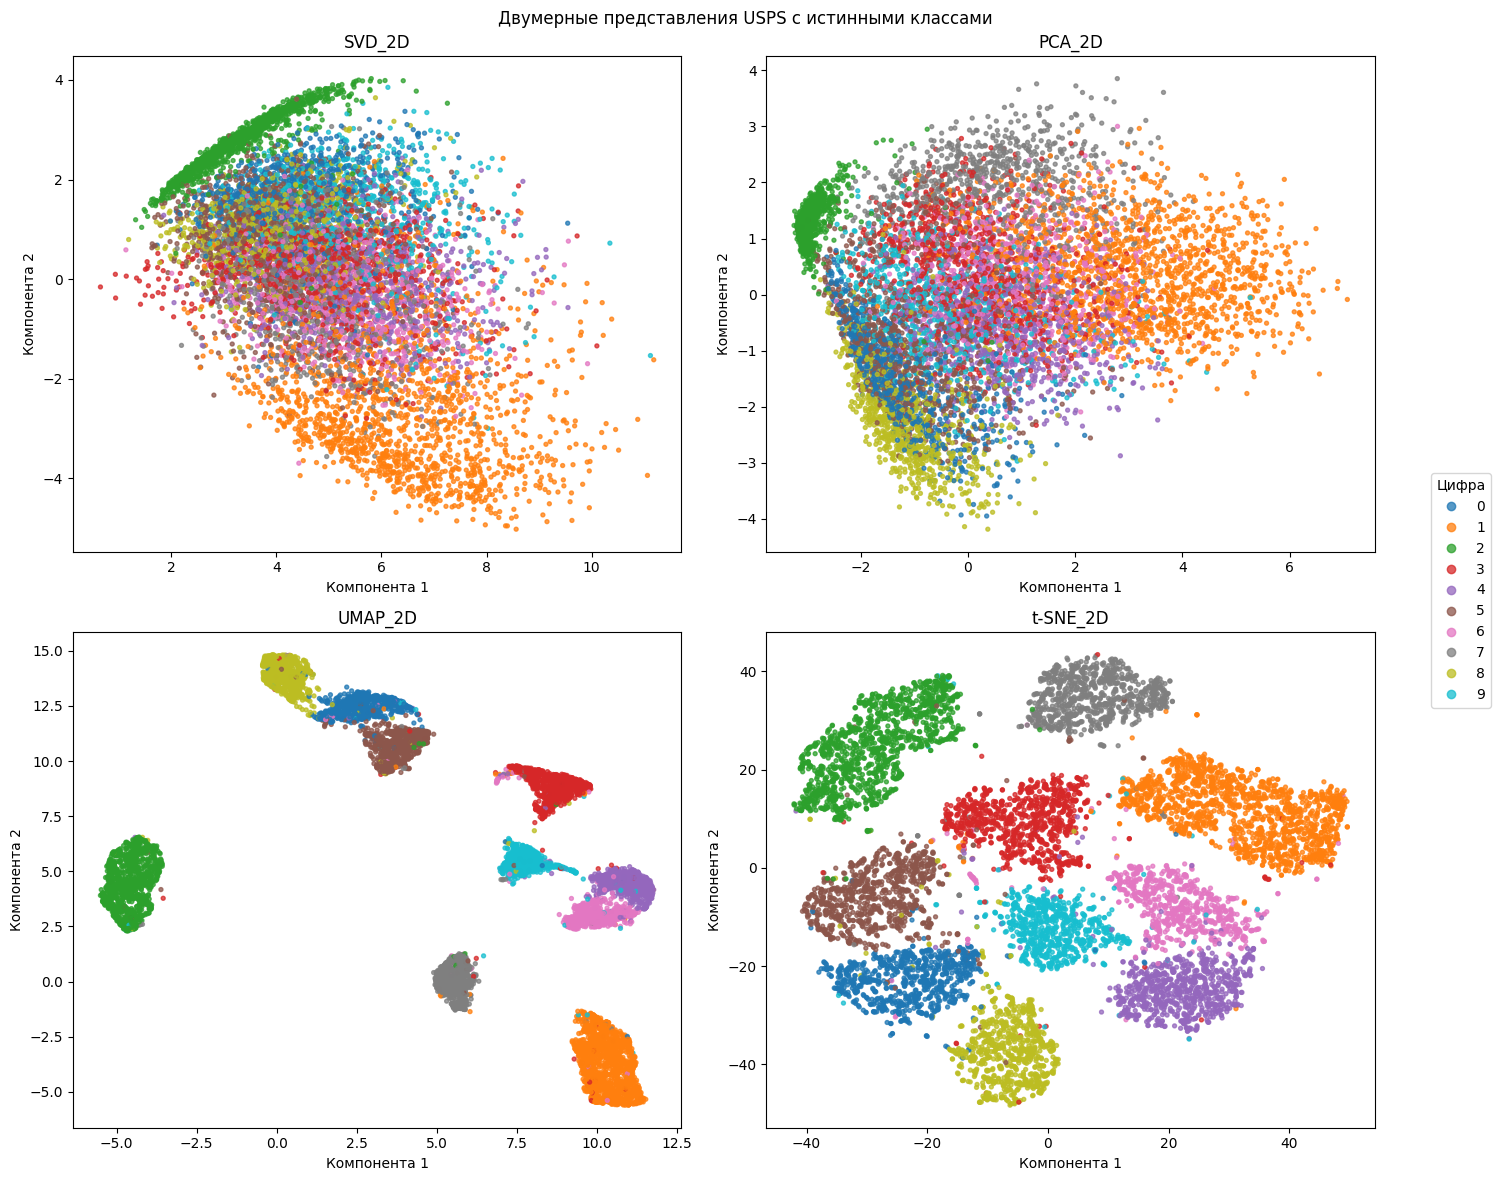

In [7]:
def plot_dr_results(dr_results, y_true):
    plot_names = ['SVD_2D', 'PCA_2D', 'UMAP_2D', 't-SNE_2D']
    fig, axes = plt.subplots(2, 2, figsize=(15, 12))
    axes = axes.flatten()

    for ax, name in zip(axes, plot_names):
        emb = dr_results[name]
        scatter = ax.scatter(emb[:, 0], emb[:, 1], c=y_true, s=8, cmap='tab10', alpha=0.75)
        ax.set_title(name)
        ax.set_xlabel('Компонента 1')
        ax.set_ylabel('Компонента 2')

    handles, _ = scatter.legend_elements()
    fig.legend(handles, class_names, title='Цифра', loc='center right')
    plt.suptitle('Двумерные представления USPS с истинными классами')
    plt.tight_layout(rect=[0, 0, 0.93, 1])
    plt.show()

plot_dr_results(dr_results, y_digits)

## Сравнение алгоритмов кластеризации

На 50-мерных и 2-мерных представлениях сравниваются центроидные, иерархические, вероятностные и BIRCH-алгоритмы. Для 2D-представлений дополнительно проверяются DBSCAN и OPTICS, потому что их проще интерпретировать на визуальных проекциях.

In [8]:
def compare_clustering_on_dr(X_dict, y_true, n_clusters=10):
    evaluator = ClusteringEvaluator(silhouette_sample=3000, random_state=RANDOM_STATE)
    clustering = ClusteringAlgorithms(random_state=RANDOM_STATE)

    base_algorithms = [
        ('KMeans', lambda X: clustering.kmeans(X, n_clusters=n_clusters)),
        ('MiniBatchKMeans', lambda X: clustering.mini_batch_kmeans(X, n_clusters=n_clusters)),
        ('Agglomerative', lambda X: clustering.agglomerative(X, n_clusters=n_clusters)),
        ('GMM', lambda X: clustering.gmm(X, n_components=n_clusters)),
        ('BIRCH', lambda X: clustering.birch(X, n_clusters=n_clusters)),
    ]

    comparison_results = {}
    for dr_name, X_dr in X_dict.items():
        print(f"\n{'#'*80}")
        print(f'АНАЛИЗ НА ПРЕДСТАВЛЕНИИ: {dr_name}')
        print(f"{'#'*80}")
        comparison_results[dr_name] = {}

        algorithms = base_algorithms.copy()
        if X_dr.shape[1] == 2:
            algorithms.extend([
                ('DBSCAN', lambda X: clustering.dbscan(X, eps=0.55, min_samples=12)),
                ('OPTICS', lambda X: clustering.optics(X, min_samples=15)),
            ])

        for algo_name, algo_func in algorithms:
            try:
                start = time.time()
                labels, model = algo_func(X_dr)
                result = evaluator.compute_all_metrics(X_dr, labels, y_true, algo_name, dr_name)
                result['Time'] = time.time() - start
                evaluator.print_metrics(result)
                comparison_results[dr_name][algo_name] = {'labels': labels, 'model': model, 'metrics': result}
            except Exception as exc:
                print(f'Ошибка {algo_name} на {dr_name}: {exc}')

    return evaluator, comparison_results

cluster_inputs = {
    'SVD_50D': dr_results['SVD_50D'],
    'PCA_50D': dr_results['PCA_50D'],
    'UMAP_50D': dr_results['UMAP_50D'],
    'SVD_2D': dr_results['SVD_2D'],
    'PCA_2D': dr_results['PCA_2D'],
    'UMAP_2D': dr_results['UMAP_2D'],
    't-SNE_2D': dr_results['t-SNE_2D'],
}

evaluator, comparison_results = compare_clustering_on_dr(cluster_inputs, y_digits, n_clusters=n_classes)
summary_df = evaluator.get_summary_dataframe()
summary_df.sort_values(['Composite', 'ARI', 'Silhouette'], ascending=False).head(20)


################################################################################
АНАЛИЗ НА ПРЕДСТАВЛЕНИИ: SVD_50D
################################################################################

DR: SVD_50D | Алгоритм: KMeans
----------------------------------------------------------------------
Кластеров: 10; шум: 0.000; Composite: 0.4670
Silhouette=0.1571; CH=905.16; DB=1.9432
ARI=0.5337; AMI=0.6095; NMI=0.6102; V=0.6102

DR: SVD_50D | Алгоритм: MiniBatchKMeans
----------------------------------------------------------------------
Кластеров: 10; шум: 0.000; Composite: 0.4487
Silhouette=0.1539; CH=880.07; DB=2.0624
ARI=0.4988; AMI=0.5874; NMI=0.5882; V=0.5882

DR: SVD_50D | Алгоритм: Agglomerative
----------------------------------------------------------------------
Кластеров: 10; шум: 0.000; Composite: 0.5410
Silhouette=0.1340; CH=781.76; DB=2.0558
ARI=0.6667; AMI=0.7724; NMI=0.7728; V=0.7728

DR: SVD_50D | Алгоритм: GMM
------------------------------------------------------------

,DR_Method,Algorithm,N_Clusters,Noise_Share,Composite,Silhouette,Calinski_Harabasz,Davies_Bouldin,ARI,AMI,NMI,Homogeneity,Completeness,V_Measure
41,t-SNE_2D,DBSCAN,4,0.994300,1.005455,0.981065,80677.765625,0.025572,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000
13,UMAP_50D,GMM,10,0.000000,0.808079,0.650342,62265.878906,0.528644,0.826205,0.876232,0.876472,0.872421,0.880560,0.876472
12,UMAP_50D,Agglomerative,10,0.000000,0.803749,0.644002,63282.828125,0.520682,0.810489,0.876871,0.877108,0.876677,0.877539,0.877108
33,UMAP_2D,BIRCH,10,0.000000,0.803057,0.650959,73507.234375,0.506213,0.801590,0.869176,0.869428,0.870033,0.868823,0.869428
29,UMAP_2D,KMeans,10,0.000000,0.802834,0.652364,73800.359375,0.503639,0.799908,0.868197,0.868450,0.869104,0.867797,0.868450
31,UMAP_2D,Agglomerative,10,0.000000,0.802210,0.647477,73110.632812,0.504613,0.801738,0.868379,0.868632,0.868904,0.868360,0.868632
10,UMAP_50D,KMeans,10,0.000000,0.801908,0.653630,64709.937500,0.514187,0.800123,0.870789,0.871038,0.871335,0.870741,0.871038
14,UMAP_50D,BIRCH,10,0.000000,0.801151,0.649315,64055.566406,0.517506,0.801067,0.871418,0.871665,0.871934,0.871396,0.871665
39,t-SNE_2D,GMM,10,0.000000,0.782495,0.485887,12545.877930,0.701988,0.924042,0.905825,0.906007,0.905440,0.906574,0.906007
11,UMAP_50D,MiniBatchKMeans,10,0.000000,0.750326,0.610268,60836.031250,0.555280,0.686803,0.832897,0.833220,0.828119,0.838386,0.833220


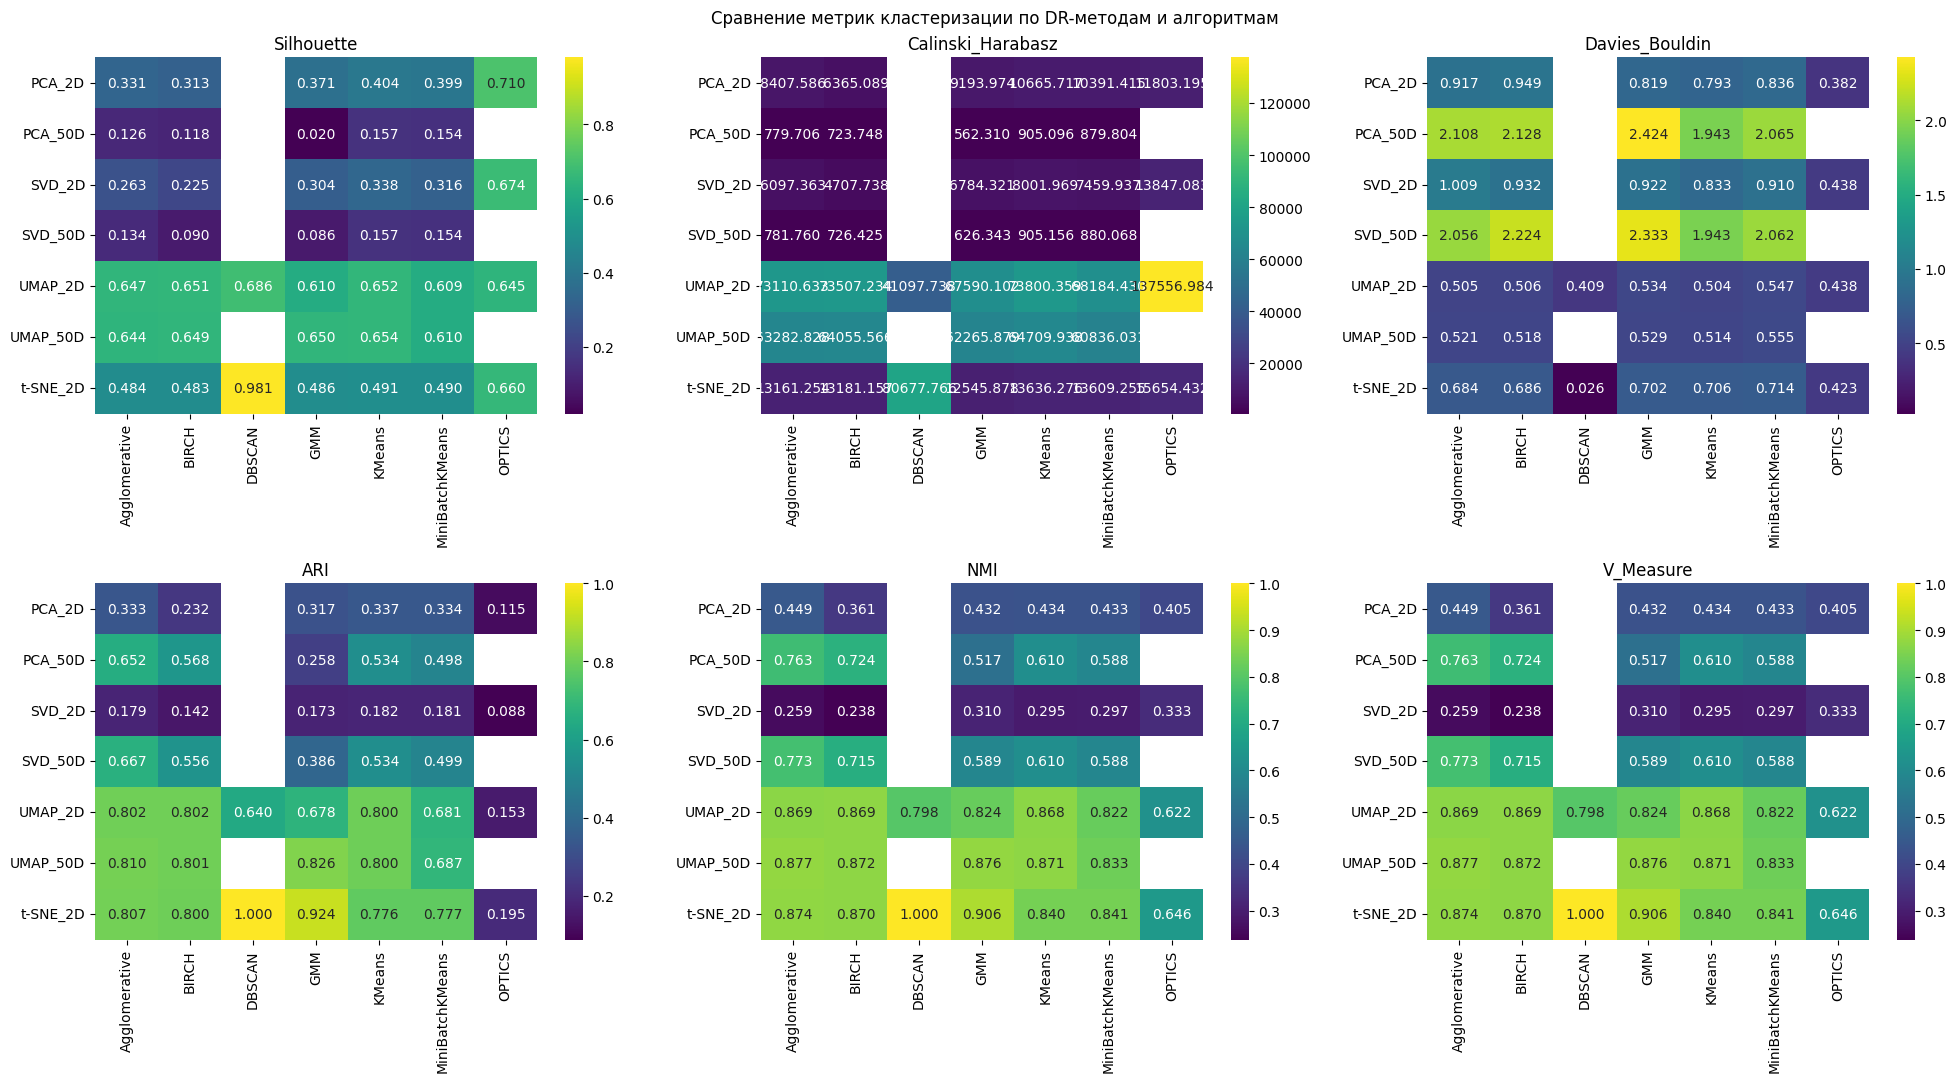

In [9]:
def visualize_metrics_comparison(summary_df):
    metrics_to_plot = ['Silhouette', 'Calinski_Harabasz', 'Davies_Bouldin', 'ARI', 'NMI', 'V_Measure']
    fig, axes = plt.subplots(2, 3, figsize=(20, 11))
    axes = axes.flatten()

    for idx, metric in enumerate(metrics_to_plot):
        ax = axes[idx]
        pivot = summary_df.pivot_table(index='DR_Method', columns='Algorithm', values=metric, aggfunc='mean')
        sns.heatmap(pivot, annot=True, fmt='.3f', cmap='viridis', ax=ax)
        ax.set_title(metric)
        ax.set_xlabel('')
        ax.set_ylabel('')

    plt.suptitle('Сравнение метрик кластеризации по DR-методам и алгоритмам')
    plt.tight_layout()
    plt.show()

visualize_metrics_comparison(summary_df)

Лучшая комбинация по комплексной оценке:


,DR_Method,Algorithm,N_Clusters,Noise_Share,Composite,Silhouette,Calinski_Harabasz,Davies_Bouldin,ARI,AMI,NMI,Homogeneity,Completeness,V_Measure
41,t-SNE_2D,DBSCAN,4,0.9943,1.005455,0.981065,80677.765625,0.025572,1.0,1.0,1.0,1.0,1.0,1.0


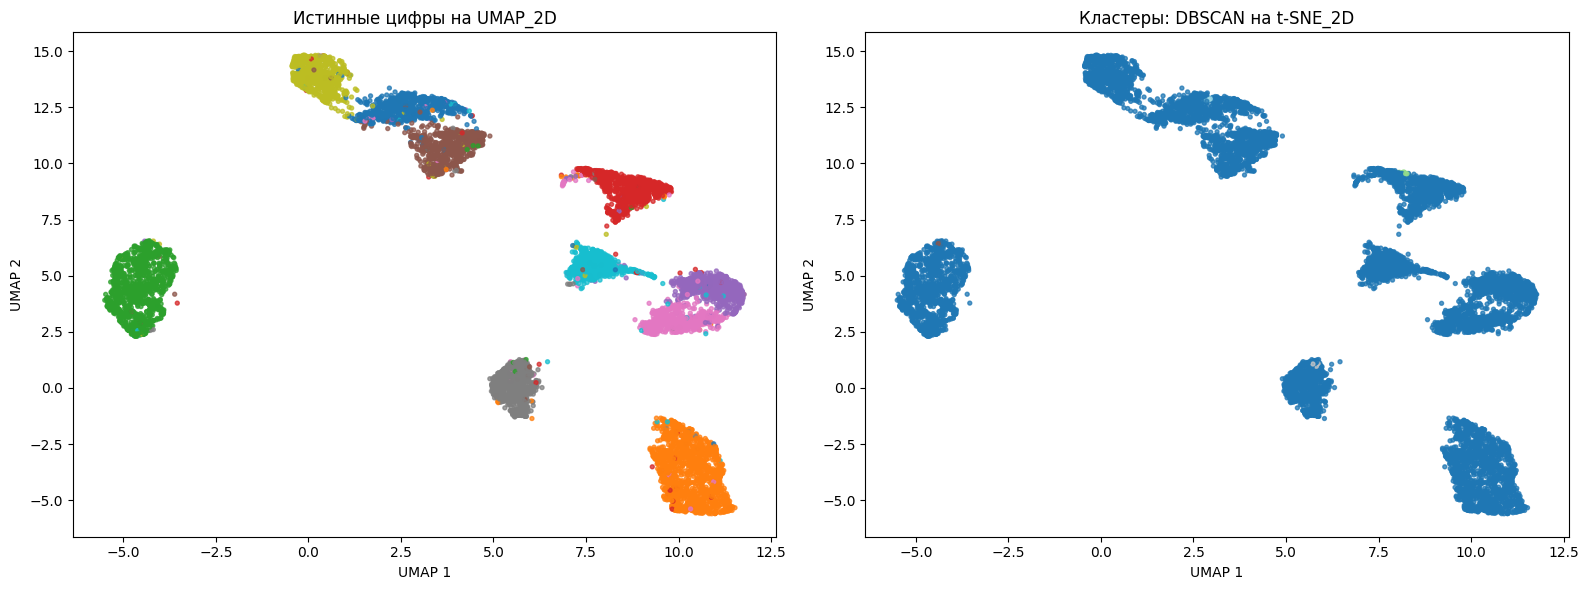

In [10]:
best_row = summary_df.sort_values(['Composite', 'ARI', 'Silhouette'], ascending=False).iloc[0]
best_dr = best_row['DR_Method']
best_algo = best_row['Algorithm']
best_labels = comparison_results[best_dr][best_algo]['labels']

print('Лучшая комбинация по комплексной оценке:')
display(best_row.to_frame().T)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
embedding = dr_results['UMAP_2D']
axes[0].scatter(embedding[:, 0], embedding[:, 1], c=y_digits, s=8, cmap='tab10', alpha=0.75)
axes[0].set_title('Истинные цифры на UMAP_2D')
axes[0].set_xlabel('UMAP 1')
axes[0].set_ylabel('UMAP 2')

axes[1].scatter(embedding[:, 0], embedding[:, 1], c=best_labels, s=8, cmap='tab20', alpha=0.75)
axes[1].set_title(f'Кластеры: {best_algo} на {best_dr}')
axes[1].set_xlabel('UMAP 1')
axes[1].set_ylabel('UMAP 2')
plt.tight_layout()
plt.show()

## Интерпретация кластеров

Для изображений вместо top-слов анализируются распределения истинных цифр внутри каждого кластера и средние изображения кластеров. Это показывает, какие цифры алгоритм объединяет уверенно, а какие смешиваются между собой.

In [11]:
def describe_digit_clusters(X, y_true, labels):
    rows = []
    for cluster in sorted(np.unique(labels)):
        if cluster == -1:
            continue
        mask = labels == cluster
        counts = Counter(y_true[mask])
        dominant_digit, dominant_count = counts.most_common(1)[0]
        rows.append({
            'cluster': int(cluster),
            'size': int(mask.sum()),
            'dominant_digit': int(dominant_digit),
            'dominant_share': dominant_count / mask.sum(),
            'digit_distribution': dict(sorted(counts.items())),
        })
    return pd.DataFrame(rows).sort_values(['dominant_share', 'size'], ascending=False)

cluster_description = describe_digit_clusters(X, y_digits, best_labels)
cluster_description

,cluster,size,dominant_digit,dominant_share,digit_distribution
0,0,14,3,1.0,{3: 14}
2,2,14,7,1.0,{7: 14}
1,1,13,2,1.0,{2: 13}
3,3,12,0,1.0,{0: 12}


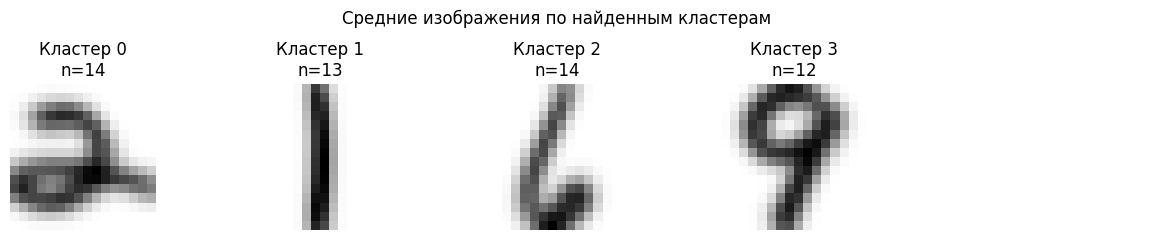

In [12]:
def plot_cluster_averages(X, labels, max_clusters=20):
    clusters = [c for c in sorted(np.unique(labels)) if c != -1][:max_clusters]
    n_cols = 5
    n_rows = int(np.ceil(len(clusters) / n_cols))
    fig, axes = plt.subplots(n_rows, n_cols, figsize=(12, 2.4 * n_rows))
    axes = np.array(axes).reshape(-1)

    for ax, cluster in zip(axes, clusters):
        avg_img = X[labels == cluster].mean(axis=0).reshape(16, 16)
        ax.imshow(avg_img, cmap='gray_r')
        ax.set_title(f'Кластер {cluster}\nn={np.sum(labels == cluster)}')
        ax.axis('off')

    for ax in axes[len(clusters):]:
        ax.axis('off')
    plt.suptitle('Средние изображения по найденным кластерам')
    plt.tight_layout()
    plt.show()

plot_cluster_averages(X, best_labels)

## Подбор числа кластеров

Так как истинно классов 10, проверяется диапазон вокруг этого значения. Визуально и по метрикам можно увидеть, насколько естественная структура данных совпадает с десятью цифрами.

,k,Silhouette,Calinski_Harabasz,Davies_Bouldin,ARI,NMI
0,6,0.161472,1142.335938,2.056294,0.426931,0.553805
1,7,0.163476,1058.766113,2.090050,0.481974,0.577782
2,8,0.161941,994.606323,2.023451,0.475775,0.573527
3,9,0.170109,950.159851,1.983110,0.530064,0.609773
4,10,0.157106,905.096130,1.943264,0.533738,0.610211
5,11,0.161913,856.481445,1.983153,0.520509,0.609944
6,12,0.159186,812.914795,1.994198,0.507206,0.609342
7,13,0.159085,777.245056,2.048624,0.502371,0.611982
8,14,0.162327,743.566223,2.027622,0.506442,0.624614
9,15,0.166871,715.417725,1.994543,0.518883,0.637080


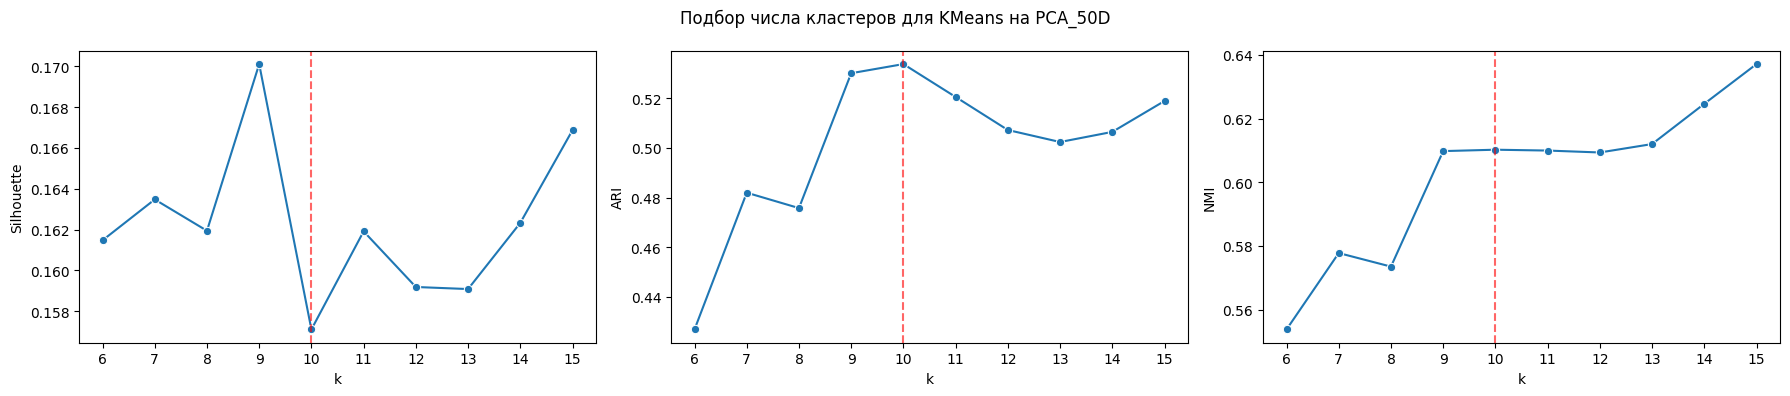

In [13]:
k_values = range(6, 16)
k_rows = []
X_k = dr_results['PCA_50D']
for k in k_values:
    labels = KMeans(n_clusters=k, random_state=RANDOM_STATE, n_init=20).fit_predict(X_k)
    k_rows.append({
        'k': k,
        'Silhouette': silhouette_score(X_k, labels, sample_size=3000, random_state=RANDOM_STATE),
        'Calinski_Harabasz': calinski_harabasz_score(X_k, labels),
        'Davies_Bouldin': davies_bouldin_score(X_k, labels),
        'ARI': adjusted_rand_score(y_digits, labels),
        'NMI': normalized_mutual_info_score(y_digits, labels),
    })

k_df = pd.DataFrame(k_rows)
display(k_df)

fig, axes = plt.subplots(1, 3, figsize=(18, 4))
sns.lineplot(data=k_df, x='k', y='Silhouette', marker='o', ax=axes[0])
sns.lineplot(data=k_df, x='k', y='ARI', marker='o', ax=axes[1])
sns.lineplot(data=k_df, x='k', y='NMI', marker='o', ax=axes[2])
for ax in axes:
    ax.axvline(10, color='red', linestyle='--', alpha=0.6)
    ax.set_xticks(list(k_values))
plt.suptitle('Подбор числа кластеров для KMeans на PCA_50D')
plt.tight_layout()
plt.show()

## Bootstrap-анализ устойчивости

Проверяется, насколько стабильно алгоритмы сохраняют качество на bootstrap-выборках полного набора данных. Метрики считаются относительно истинных цифр, но сами алгоритмы обучаются без использования меток.

In [14]:
def evaluate_stability(X_dict, y_true, n_clusters=10, n_bootstrap=8, random_state=42):
    rng = np.random.default_rng(random_state)
    algorithms = {
        'KMeans': lambda X, seed: KMeans(n_clusters=n_clusters, random_state=seed, n_init=10).fit_predict(X),
        'MiniBatchKMeans': lambda X, seed: MiniBatchKMeans(n_clusters=n_clusters, random_state=seed, n_init=10, batch_size=1024).fit_predict(X),
        'GMM': lambda X, seed: GaussianMixture(n_components=n_clusters, random_state=seed, covariance_type='diag', reg_covar=1e-5).fit_predict(X),
        'BIRCH': lambda X, seed: Birch(n_clusters=n_clusters, threshold=0.5).fit(X).labels_,
    }

    rows = []
    for dr_name, X_dr in X_dict.items():
        for algo_name, algo_func in algorithms.items():
            ari_values, nmi_values, sil_values = [], [], []
            for i in range(n_bootstrap):
                idx = rng.choice(X_dr.shape[0], size=X_dr.shape[0], replace=True)
                X_boot = X_dr[idx]
                y_boot = y_true[idx]
                try:
                    labels = algo_func(X_boot, random_state + i)
                except Exception:
                    continue
                if len(np.unique(labels)) > 1:
                    ari_values.append(adjusted_rand_score(y_boot, labels))
                    nmi_values.append(normalized_mutual_info_score(y_boot, labels))
                    sil_values.append(silhouette_score(X_boot, labels, sample_size=3000, random_state=random_state))
            rows.append({
                'DR_Method': dr_name,
                'Algorithm': algo_name,
                'ARI_mean': np.mean(ari_values) if ari_values else np.nan,
                'ARI_std': np.std(ari_values) if ari_values else np.nan,
                'NMI_mean': np.mean(nmi_values) if nmi_values else np.nan,
                'NMI_std': np.std(nmi_values) if nmi_values else np.nan,
                'Silhouette_mean': np.mean(sil_values) if sil_values else np.nan,
                'Silhouette_std': np.std(sil_values) if sil_values else np.nan,
            })
    return pd.DataFrame(rows).sort_values(['ARI_mean', 'NMI_mean'], ascending=False)

stability_df = evaluate_stability(
    {'SVD_50D': dr_results['SVD_50D'], 'PCA_50D': dr_results['PCA_50D'], 'UMAP_50D': dr_results['UMAP_50D']},
    y_digits,
    n_clusters=n_classes,
    n_bootstrap=8,
)
stability_df

,DR_Method,Algorithm,ARI_mean,ARI_std,NMI_mean,NMI_std,Silhouette_mean,Silhouette_std
10,UMAP_50D,GMM,0.838092,0.056375,0.885837,0.017134,0.660787,0.018520
9,UMAP_50D,MiniBatchKMeans,0.816362,0.060496,0.873236,0.017686,0.656566,0.019198
11,UMAP_50D,BIRCH,0.815590,0.013367,0.876975,0.002984,0.653959,0.007746
8,UMAP_50D,KMeans,0.802746,0.010982,0.873394,0.005198,0.660466,0.003534
7,PCA_50D,BIRCH,0.610647,0.025040,0.734087,0.013484,0.129099,0.020770
3,SVD_50D,BIRCH,0.572692,0.046820,0.703540,0.028571,0.132526,0.014653
4,PCA_50D,KMeans,0.539322,0.003381,0.617943,0.003388,0.161495,0.001800
0,SVD_50D,KMeans,0.529912,0.009057,0.610207,0.006406,0.159501,0.003435
5,PCA_50D,MiniBatchKMeans,0.495654,0.033275,0.590754,0.022132,0.164332,0.008220
1,SVD_50D,MiniBatchKMeans,0.488708,0.029925,0.586566,0.019570,0.161678,0.005446


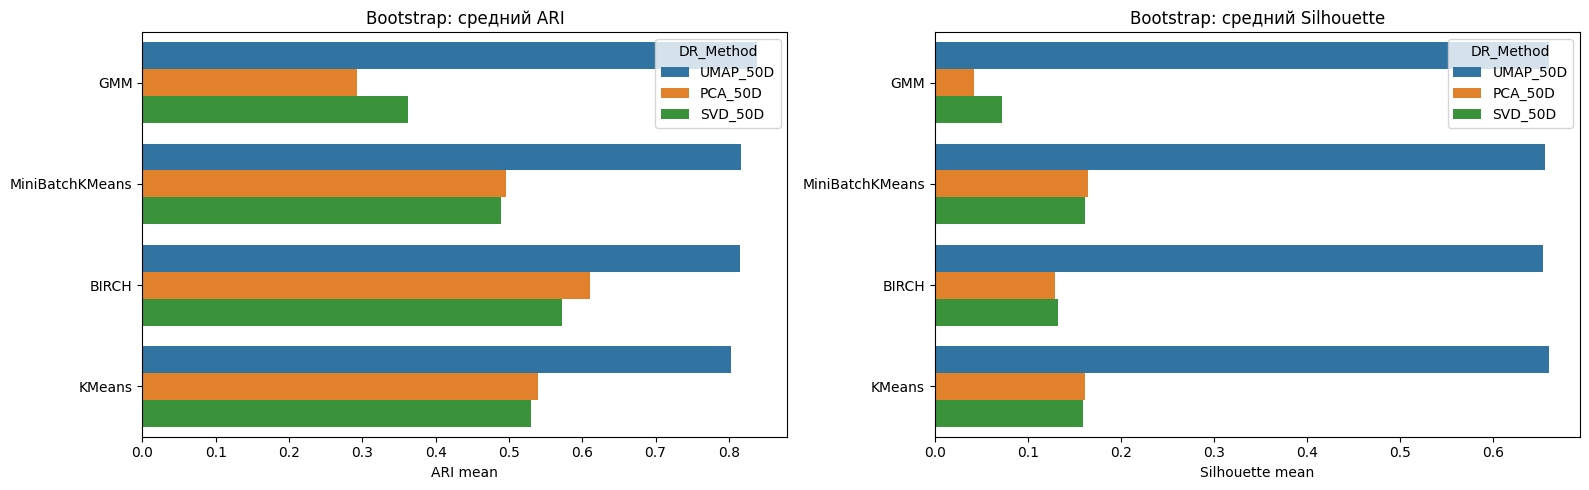

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5))
sns.barplot(data=stability_df, x='ARI_mean', y='Algorithm', hue='DR_Method', ax=axes[0])
axes[0].set_title('Bootstrap: средний ARI')
axes[0].set_xlabel('ARI mean')
axes[0].set_ylabel('')

sns.barplot(data=stability_df, x='Silhouette_mean', y='Algorithm', hue='DR_Method', ax=axes[1])
axes[1].set_title('Bootstrap: средний Silhouette')
axes[1].set_xlabel('Silhouette mean')
axes[1].set_ylabel('')
plt.tight_layout()
plt.show()

## Выводы

USPS оказался более сложной задачей для кластеризации: визуально похожие цифры смешиваются, а оптимальное разбиение не всегда полностью совпадает с десятью истинными классами. Линейные методы PCA/SVD дают устойчивые базовые представления, UMAP лучше сохраняет локальную структуру для визуального анализа, а качество алгоритмов заметно зависит от выбранного пространства признаков.

Лучшее решение выбирается по комплексной оценке, где учитываются внутренние метрики компактности/разделимости и внешние метрики относительно истинных цифр. Bootstrap-анализ дополнительно показывает, какие сочетания метода понижения размерности и кластеризации стабильнее на повторных выборках.